# 1 - Load the dataset information

In [20]:
from pathlib import Path
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
import shutil
from sklearn.model_selection import train_test_split
import cv2

cwd = Path.cwd()
root = cwd.parent
data_dir = root / "data"
classification_dir = data_dir / "Classification"

data = {}

filenames = []
paths = []
widths = []
heights = []
channels = []
splits = []
classes = []

for folder in classification_dir.iterdir():
    for classname in folder.iterdir():
        for file in classname.iterdir() :
            img = cv2.imread(file,cv2.IMREAD_UNCHANGED)
            shape = img.shape
            width = shape[0]
            height = shape[1]
            channel = shape[2] if len(shape) > 2 else 1

            filenames.append(file.name)
            paths.append(file)
            heights.append(height)
            widths.append(width)
            channels.append(channel)
            splits.append(folder.name)
            classes.append(classname.name)

data["Filename"] = filenames
data["Path"] = paths
data["Width"] = widths
data["Height"] = heights
data["Channel"] = channels
data["Split"] = splits
data["Class"] = classes

df = pd.DataFrame(data)
display(df.head(5))
display(df.tail(5))

,Filename,Path,Width,Height,Channel,Split,Class
0,Tr-gl_1062.jpg,/home/walid/Documents/BrainScan_v2/data/Classi...,512,512,1,test,glioma
1,Tr-gl_1080.jpg,/home/walid/Documents/BrainScan_v2/data/Classi...,512,512,1,test,glioma
2,Te-gl_0193.jpg,/home/walid/Documents/BrainScan_v2/data/Classi...,512,512,1,test,glioma
3,Tr-gl_0882.jpg,/home/walid/Documents/BrainScan_v2/data/Classi...,512,512,1,test,glioma
4,Tr-gl_0496.jpg,/home/walid/Documents/BrainScan_v2/data/Classi...,512,512,1,test,glioma


,Filename,Path,Width,Height,Channel,Split,Class
7018,Tr-no_0083.jpg,/home/walid/Documents/BrainScan_v2/data/Classi...,216,236,3,train,notumor
7019,Tr-no_0012.jpg,/home/walid/Documents/BrainScan_v2/data/Classi...,630,630,3,train,notumor
7020,Tr-no_1183.jpg,/home/walid/Documents/BrainScan_v2/data/Classi...,262,236,3,train,notumor
7021,Tr-no_0018.jpg,/home/walid/Documents/BrainScan_v2/data/Classi...,442,332,3,train,notumor
7022,Tr-no_0090.jpg,/home/walid/Documents/BrainScan_v2/data/Classi...,232,236,3,train,notumor


# 2 - Explore class distribution

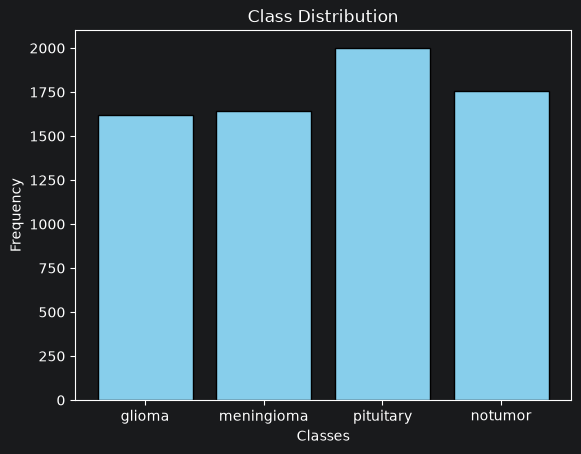

In [21]:
classes = df["Class"].unique()
counts = df.groupby("Class")["Filename"].count()

plt.bar(classes,counts,color="skyblue",edgecolor="black")

plt.title("Class Distribution")
plt.xlabel("Classes")
plt.ylabel("Frequency")

plt.show()

# 4 - Visualize representative images

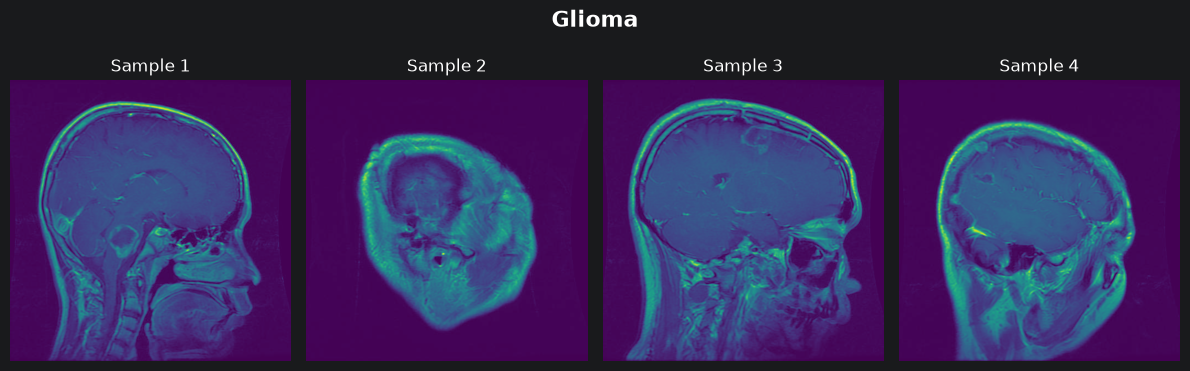

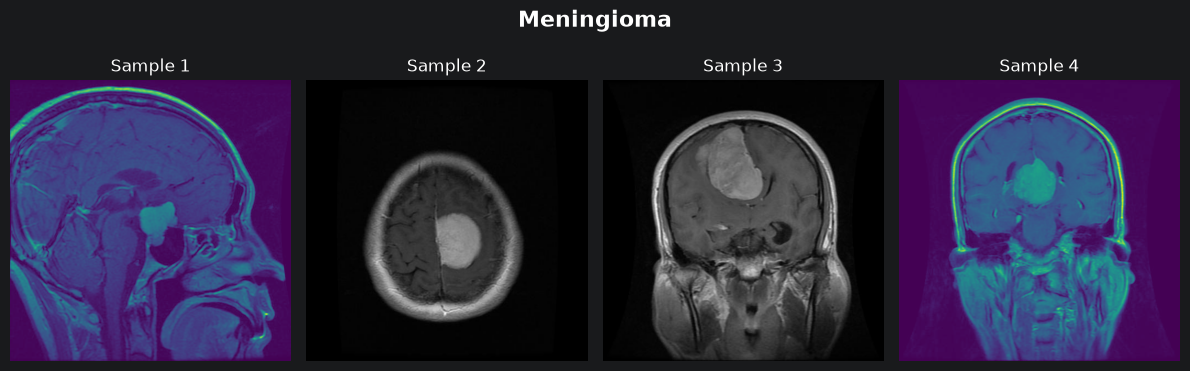

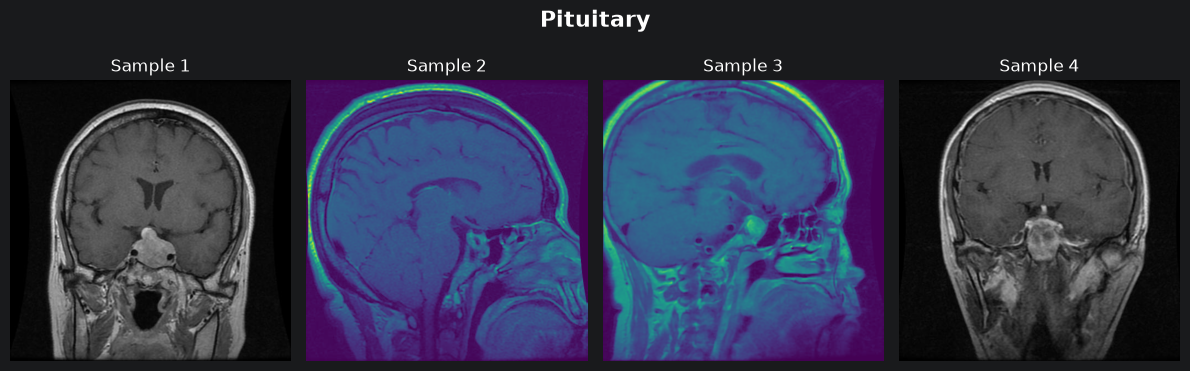

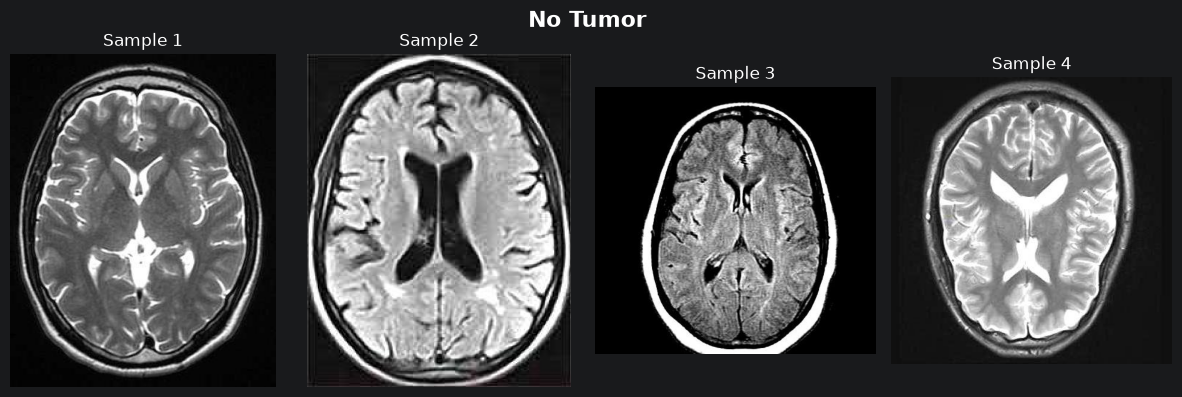

In [24]:
glioma = df[df["Class"] == "glioma"]["Path"]
meningioma = df[df["Class"] == "meningioma"]["Path"]
pituitary = df[df["Class"] == "pituitary"]["Path"]
notumor = df[df["Class"] == "notumor"]["Path"]

folders = {
    "Glioma" : glioma,
    "Meningioma" : meningioma,
    "Pituitary" : pituitary,
    "No Tumor" : notumor
}

for name,paths in folders.items() :
    samples = list(paths)[:4]

    fig,axes = plt.subplots(1,4,figsize=(12,4))
    for index , path in enumerate(samples):
        img = mpimg.imread(path)

        axes[index].imshow(img)
        axes[index].set_title(f"Sample {index+1}")
        axes[index].axis("off")

    fig.suptitle(name, fontsize=16, fontweight='bold')

    plt.tight_layout()
    plt.show()